In [1]:
#Experiment 1: FIND-S Algorithm
import pandas as pd

data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Weak', 'No'],
    ['Sunny', 'Warm', 'High', 'Weak', 'Yes']
]

h = ['0', '0', '0', '0']

for row in data:
    if row[-1] == 'Yes':
        for i in range(len(h)):
            if h[i] == '0':
                h[i] = row[i]
            elif h[i] != row[i]:
                h[i] = '?'

print("Final Hypothesis:", h)

Final Hypothesis: ['Sunny', 'Warm', '?', '?']


In [2]:
#Experiment 2: Candidate-Elimination Algorithm
data = [
    ['Sunny', 'Warm', 'Normal', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Yes'],
    ['Rainy', 'Cold', 'High', 'No'],
    ['Sunny', 'Warm', 'High', 'Yes']
]

S = ['0', '0', '0']
G = [['?', '?', '?']]

for row in data:
    x, label = row[:-1], row[-1]

    if label == 'Yes':
        for i in range(len(S)):
            if S[i] == '0':
                S[i] = x[i]
            elif S[i] != x[i]:
                S[i] = '?'
    else:
        new_G = []
        for g in G:
            for i in range(len(g)):
                if g[i] == '?' and S[i] != '?' and S[i] != '0' and S[i] != x[i]:
                    temp = g.copy()
                    temp[i] = S[i]
                    new_G.append(temp)
        G = new_G

print("Specific Boundary:", S)
print("General Boundary:", G)

Specific Boundary: ['Sunny', 'Warm', '?']
General Boundary: [['Sunny', '?', '?'], ['?', 'Warm', '?']]


In [3]:
#Experiment 3: Decision Tree using ID3
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

data = pd.DataFrame({
    'Weather': ['Sunny', 'Rainy', 'Sunny', 'Rainy', 'Sunny'],
    'Temperature': ['Hot', 'Cold', 'Mild', 'Cold', 'Hot'],
    'Play': ['No', 'Yes', 'Yes', 'Yes', 'No']
})

encoders = {}
for col in data.columns:
    encoders[col] = LabelEncoder()
    data[col] = encoders[col].fit_transform(data[col])

X = data[['Weather', 'Temperature']]
y = data['Play']

model = DecisionTreeClassifier(criterion='entropy', random_state=0)
model.fit(X, y)

sample = [[
    encoders['Weather'].transform(['Sunny'])[0],
    encoders['Temperature'].transform(['Mild'])[0]
]]

prediction = model.predict(sample)[0]
print("Prediction:", encoders['Play'].inverse_transform([prediction])[0])

Prediction: Yes


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [4]:
#Experiment 4: Artificial Neural Network using Backpropagation
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000,
                      random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))

Accuracy: 1.0


In [5]:
#Experiment 5: K-Nearest Neighbours (KNN)
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
print("Prediction:", model.predict([X_test[0]]))

Accuracy: 1.0
Prediction: [1]


In [6]:
#Experiment 6: Naive Bayes with Confusion Matrix
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = GaussianNB()
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred))

Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [7]:
#Experiment 7: Logistic Regression
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
print("Prediction:", model.predict([X_test[0]]))

Accuracy: 1.0
Prediction: [1]


In [8]:
#Experiment 8: Linear Regression
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 4, 6, 8, 10])

model = LinearRegression()
model.fit(X, y)

pred = model.predict(X)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)
print("MSE:", mean_squared_error(y, pred))
print("Prediction for 6:", model.predict([[6]])[0])

Coefficient: 2.0
Intercept: 0.0
MSE: 0.0
Prediction for 6: 12.0


Linear MSE: 2.7999999999999985
Polynomial MSE: 1.5146129380243426e-29


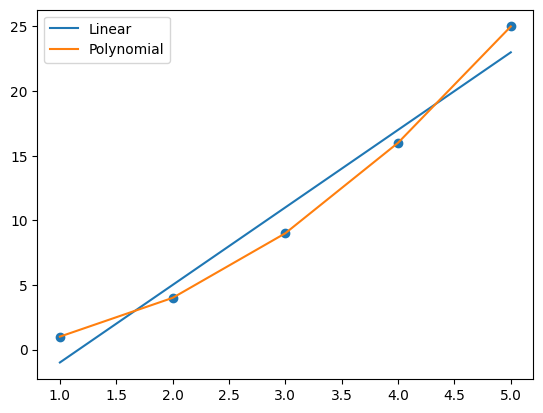

In [9]:
#Experiment 9: Linear vs Polynomial Regression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 4, 9, 16, 25])

linear = LinearRegression().fit(X, y)
linear_pred = linear.predict(X)

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

polynomial = LinearRegression().fit(X_poly, y)
poly_pred = polynomial.predict(X_poly)

print("Linear MSE:", mean_squared_error(y, linear_pred))
print("Polynomial MSE:", mean_squared_error(y, poly_pred))

plt.scatter(X, y)
plt.plot(X, linear_pred, label="Linear")
plt.plot(X, poly_pred, label="Polynomial")
plt.legend()
plt.show()

Cluster Labels: [0 0 0 1 1 1]
Cluster Means:
 [[1.33333333 1.33333333]
 [8.33333333 8.33333333]]


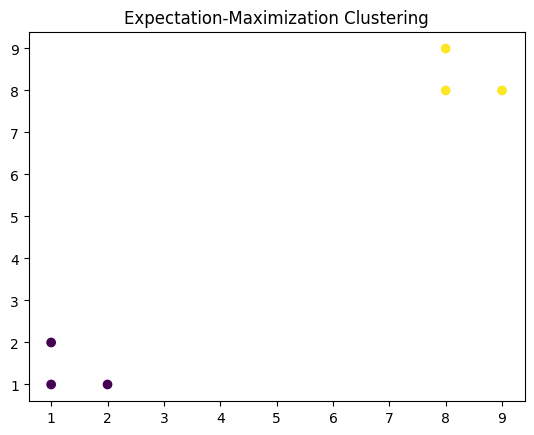

In [10]:
#Experiment 10: Expectation-Maximization Algorithm
import numpy as np
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

X = np.array([
    [1, 2], [1, 1], [2, 1],
    [8, 9], [9, 8], [8, 8]
])

model = GaussianMixture(n_components=2, random_state=42)
model.fit(X)

labels = model.predict(X)

print("Cluster Labels:", labels)
print("Cluster Means:\n", model.means_)

plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.title("Expectation-Maximization Clustering")
plt.show()

In [11]:
#Experiment 11: Credit Score Classification
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

data = pd.DataFrame({
    'Income': [20000, 50000, 80000, 30000, 90000, 60000],
    'Debt': [18000, 10000, 5000, 20000, 8000, 12000],
    'CreditScore': ['Low', 'Medium', 'High', 'Low', 'High', 'Medium']
})

X = data[['Income', 'Debt']]
y = data['CreditScore']

model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

print("Predicted Credit Score:",
      model.predict([[70000, 10000]])[0])

Predicted Credit Score: Medium


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [12]:
#Experiment 12: Iris Classification using KNN
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))
print("Flower:", iris.target_names[
    model.predict([[5.1, 3.5, 1.4, 0.2]])[0]
])

Accuracy: 1.0
Flower: setosa


In [13]:
#Experiment 13: Car Price Prediction
import pandas as pd
from sklearn.linear_model import LinearRegression

data = pd.DataFrame({
    'Year': [2015, 2017, 2018, 2020, 2021, 2022],
    'Kilometers': [80000, 60000, 50000, 30000, 20000, 10000],
    'Price': [3, 4, 5, 7, 8, 10]
})

X = data[['Year', 'Kilometers']]
y = data['Price']

model = LinearRegression()
model.fit(X, y)

price = model.predict([[2020, 25000]])
print("Predicted Car Price:", round(price[0], 2), "Lakhs")

Predicted Car Price: 7.8 Lakhs


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [14]:
#Experiment 14: House Price Prediction
import pandas as pd
from sklearn.linear_model import LinearRegression

data = pd.DataFrame({
    'Area': [800, 1000, 1200, 1500, 1800, 2000],
    'Bedrooms': [1, 2, 2, 3, 3, 4],
    'Price': [20, 25, 30, 40, 45, 55]
})

X = data[['Area', 'Bedrooms']]
y = data['Price']

model = LinearRegression()
model.fit(X, y)

prediction = model.predict([[1400, 3]])
print("Predicted House Price:", round(prediction[0], 2), "Lakhs")

Predicted House Price: 37.9 Lakhs


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [15]:
#Experiment 15: Iris Classification using Naive Bayes
from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = GaussianNB()
model.fit(X_train, y_train)

print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))

result = model.predict([[6.1, 2.8, 4.7, 1.2]])
print("Predicted Flower:", iris.target_names[result[0]])


Accuracy: 1.0
Predicted Flower: versicolor


In [16]:
#Experiment 16: Compare Classification Algorithms
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "Accuracy:", round(accuracy_score(y_test, pred), 3))

KNN Accuracy: 1.0
Naive Bayes Accuracy: 1.0
Decision Tree Accuracy: 1.0
Logistic Regression Accuracy: 1.0
Random Forest Accuracy: 1.0


In [17]:
#Experiment 17: Mobile Price Prediction
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

data = pd.DataFrame({
    'RAM': [2, 3, 4, 6, 8, 12],
    'Battery': [2000, 2500, 3000, 3500, 4000, 5000],
    'Storage': [16, 32, 64, 64, 128, 256],
    'PriceRange': [0, 0, 1, 2, 3, 3]
})

X = data[['RAM', 'Battery', 'Storage']]
y = data['PriceRange']

model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

prediction = model.predict([[6, 4000, 128]])
print("Predicted Price Range:", prediction[0])

Predicted Price Range: 3


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [18]:
#Experiment 18: Perceptron-based Iris Classification
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

# Binary classification: Setosa versus other flowers
y = (y == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Perceptron(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))
print("1 = Setosa, 0 = Other flower")

Accuracy: 1.0
1 = Setosa, 0 = Other flower


In [21]:
#Experiment 19: Bank Loan Prediction using Naive Bayes
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

data = pd.DataFrame({
    'Income': [20000, 50000, 70000, 30000, 90000, 60000],
    'CreditHistory': ['Bad', 'Good', 'Good', 'Bad', 'Good', 'Good'],
    'LoanApproved': ['No', 'Yes', 'Yes', 'No', 'Yes', 'Yes']
})

# Use separate encoders for each column to avoid overwriting
credit_encoder = LabelEncoder()
loan_encoder = LabelEncoder()

data['CreditHistory'] = credit_encoder.fit_transform(data['CreditHistory'])
data['LoanApproved'] = loan_encoder.fit_transform(data['LoanApproved'])

X = data[['Income', 'CreditHistory']]
y = data['LoanApproved']

model = GaussianNB()
model.fit(X, y)

prediction = model.predict([[55000, credit_encoder.transform(['Good'])[0]]])
print("Loan Decision:", "Approved" if prediction[0] == 1 else "Not Approved")

Loan Decision: Approved


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


Month 13: Predicted Sales = 289.70
Month 14: Predicted Sales = 305.68
Month 15: Predicted Sales = 321.66


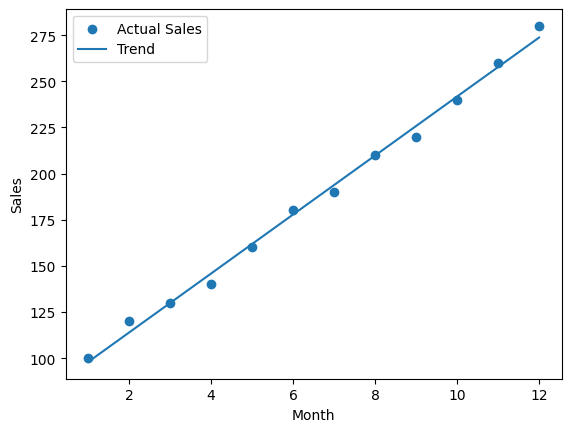

In [22]:
#Experiment 20: Future Sales Prediction
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Sample monthly sales
months = np.arange(1, 13).reshape(-1, 1)
sales = np.array([100, 120, 130, 140, 160, 180,
                  190, 210, 220, 240, 260, 280])

model = LinearRegression()
model.fit(months, sales)

future_months = np.array([[13], [14], [15]])
future_sales = model.predict(future_months)

for month, sale in zip([13, 14, 15], future_sales):
    print(f"Month {month}: Predicted Sales = {sale:.2f}")

plt.scatter(months, sales, label="Actual Sales")
plt.plot(months, model.predict(months), label="Trend")
plt.legend()
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()